# EDA del dataset BTC horario (DAT-08)

Responde las preguntas de la sección 3 de `docs/08_datos_y_entrada_modelo.md` **antes** de entrenar, porque deciden si hay algo que aprender.

- **Datos:** `data/processed/btc_updown_1h_v1/`, construido con `make dataset` (DAT-05).
- **Solo train.** Val y test no se miran, para no contaminar la evaluación (`docs/05_testing.md`, "Aislamiento del test", y S11).
- **Grilla de análisis:** un instante por minuto de cada ventana, con el último dato disponible en ese instante. Es la opción A de S3, que sigue pendiente, y aquí se usa solo para describir los datos; no es el contrato de `steps`.
- **Cómo regenerarlo:** `make eda`. Las figuras también se guardan en `docs/images/eda/` para el informe.

## 0. Preparación

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from polym4v.utils.config import DataConfig, load_config
from polym4v.utils.paths import get_paths

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CONFIG = load_config(ROOT / "configs" / "data.yaml", DataConfig)
DATASET = get_paths(env_file=ROOT / ".env", root=ROOT).processed / CONFIG.dataset_id
FIGURAS = ROOT / "docs" / "images" / "eda"
FIGURAS.mkdir(parents=True, exist_ok=True)

# Costos de S5 y el ADR-009: medio spread de 0,01 y comisión crypto_fees_v2.
MEDIO_SPREAD = 0.01
FEE_RATE = 0.07

plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})


def guardar(fig, nombre):
    """Guarda la figura en docs/images/eda para el informe."""
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=110, bbox_inches="tight")


def comision(precio):
    return FEE_RATE * precio * (1 - precio)

## 1. Carga, solo train

In [2]:
markets = pd.read_parquet(DATASET / "markets.parquet")
manifest = json.loads((DATASET / "manifest.json").read_text(encoding="utf-8"))
train = markets[markets["split"] == "train"].reset_index(drop=True)
del markets  # val y test no se miran (docs/05_testing.md, "Aislamiento del test")

ids = set(train["market_id"])
prices = pd.read_parquet(DATASET / "prices_raw.parquet")
prices = prices[prices["market_id"].isin(ids)]
spot = pd.read_parquet(DATASET / "spot_1m.parquet")
spot = spot[spot["ts_event"] < train["w1"].max()]
assert set(train["split"]) == {"train"} and prices["market_id"].isin(ids).all()

desde, hasta = pd.to_datetime([train["w0"].min(), train["w1"].max()], unit="s", utc=True)
print(f"Mercados de train: {len(train):,} (del {desde:%d/%m/%Y} al {hasta:%d/%m/%Y})")
con_comision = int(train["fees_enabled"].sum())
print(f"Con comisión: {con_comision:,}; sin comisión: {len(train) - con_comision:,}")
print(f"Tasa de UP: {train['outcome'].mean():.3f}")

Mercados de train: 8,683 (del 28/05/2025 al 27/05/2026)
Con comisión: 1,971; sin comisión: 6,712
Tasa de UP: 0.501


## 2. Grilla de análisis

Para cada mercado y minuto `k` se calculan:

- `p` y `p_stale_s`: el último precio YES disponible y su antigüedad.
- `p_next`: el primer precio posterior, como mucho 60 s después; es lo que se pagaría si la orden se ejecuta en el precio siguiente (S4).
- `x`, `sigma`, `p_fair` y `edge`: las features 5, 8, 11 y 12 de la sección 4.1 de `docs/08`.

In [3]:
# Un instante por minuto de la ventana. En cada t se toma el último precio y la última kline ya
# disponibles (la opción A de S3, todavía pendiente), solo para describir los datos.
grilla = train[["market_id", "w0", "outcome", "spot_open", "fees_enabled"]].merge(
    pd.DataFrame({"k": range(CONFIG.window_minutes)}), how="cross"
)
grilla["t"] = grilla["w0"] + CONFIG.step_seconds * grilla["k"]
yes = prices[prices["side"] == "yes"]
grilla = pd.merge_asof(
    grilla.sort_values("t"),
    yes.sort_values("ts_available")[["market_id", "ts_available", "ts_event", "p"]],
    left_on="t",
    right_on="ts_available",
    by="market_id",
    direction="backward",
)
grilla["p_stale_s"] = grilla["t"] - grilla["ts_event"]

# Primer precio posterior a t, como mucho 60 s después: lo que se pagaría si la orden se
# ejecutara en el precio siguiente (S4, pendiente).
siguiente = yes.sort_values("ts_event")[["market_id", "ts_event", "p"]]
grilla = pd.merge_asof(
    grilla.sort_values("t"),
    siguiente.rename(columns={"ts_event": "ts_next", "p": "p_next"}),
    left_on="t",
    right_on="ts_next",
    by="market_id",
    direction="forward",
    allow_exact_matches=False,
    tolerance=60,
)

# Spot: close de la última kline cerrada; volatilidad: desviación de los retornos de 1 minuto
# de la hora previa. Valor justo: probabilidad de UP si el spot sigue un paseo aleatorio.
spot = spot.sort_values("ts_available").assign(r=lambda d: np.log(d["close"]).diff())
spot["sigma"] = spot["r"].rolling(60).std()
grilla = pd.merge_asof(
    grilla.sort_values("t"),
    spot[["ts_available", "close", "sigma"]].rename(columns={"ts_available": "ts_spot"}),
    left_on="t",
    right_on="ts_spot",
    direction="backward",
)
grilla["x"] = np.log(grilla["close"] / grilla["spot_open"])
minutos = CONFIG.window_minutes - grilla["k"]
grilla["z"] = (grilla["x"] / (grilla["sigma"] * np.sqrt(minutos))).clip(-5, 5)
grilla["p_fair"] = 0.5 * (1 + grilla["z"].map(lambda z: math.erf(z / math.sqrt(2))))
grilla["edge"] = grilla["p_fair"] - grilla["p"]
grilla = grilla.sort_values(["market_id", "k"]).reset_index(drop=True)

print(f"Filas: {len(grilla):,}")
print(f"Sin precio previo: {grilla['p'].isna().mean():.4%}")
print(f"Sin precio siguiente en 60 s: {grilla['p_next'].isna().mean():.2%}")

Filas: 520,980
Sin precio previo: 0.0008%
Sin precio siguiente en 60 s: 0.37%


## 3. ¿Qué tan buenos son los datos?

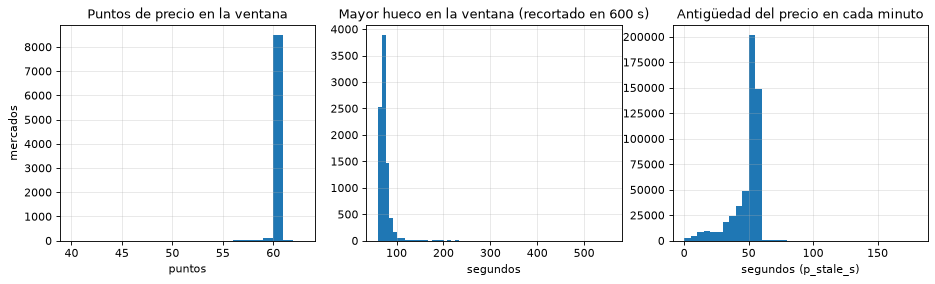

       n_points_window  max_gap_s
count           8683.0     8683.0
mean              60.0       74.9
std                0.4       21.4
min               46.0       60.0
1%                59.0       61.0
50%               60.0       74.0
99%               60.0      155.0
max               61.0      555.0

Descartados por motivo (todos los splits, solo el conteo):
precio fuera de rango           3
hueco largo en la ventana       5
pocos puntos en la ventana     51
excluido de test (S11)        109

count    520976.0
mean         48.2
std          19.7
min           0.0
10%          32.0
50%          52.0
90%          57.0
99%          58.0
max        3519.0


In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.5))
ejes[0].hist(train["n_points_window"], bins=range(40, 64))
ejes[0].set(title="Puntos de precio en la ventana", xlabel="puntos", ylabel="mercados")
ejes[1].hist(train["max_gap_s"].clip(upper=600), bins=60)
ejes[1].set(title="Mayor hueco en la ventana (recortado en 600 s)", xlabel="segundos")
ejes[2].hist(grilla["p_stale_s"].dropna().clip(upper=180), bins=range(0, 185, 5))
ejes[2].set(title="Antigüedad del precio en cada minuto", xlabel="segundos (p_stale_s)")
guardar(fig, "01_calidad")
plt.show()

print(train[["n_points_window", "max_gap_s"]].describe(percentiles=[0.01, 0.5, 0.99]).round(1))
print()
print("Descartados por motivo (todos los splits, solo el conteo):")
print(pd.Series(manifest["discarded_by_reason"]).to_string())
print()
print(grilla["p_stale_s"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(1).to_string())

### Lectura

- Los datos son buenos: casi todos los mercados de train tienen 60 puntos en la ventana (el 1 % más bajo, 59) y el mayor hueco típico es de 74 s. Los filtros descartaron 59 mercados de unos 12 400 (0,5 %); los 109 de S11 salen de test a propósito.
- El precio llega **una vez por minuto** y, en cada instante de decisión, el último punto tiene una antigüedad mediana de **52 s** (90 % por debajo de 57 s). Cada decisión se toma con un precio de casi un minuto atrás. Esto pesa en todo lo que sigue.

## 4. ¿Qué tan calibrado está el precio minuto a minuto?

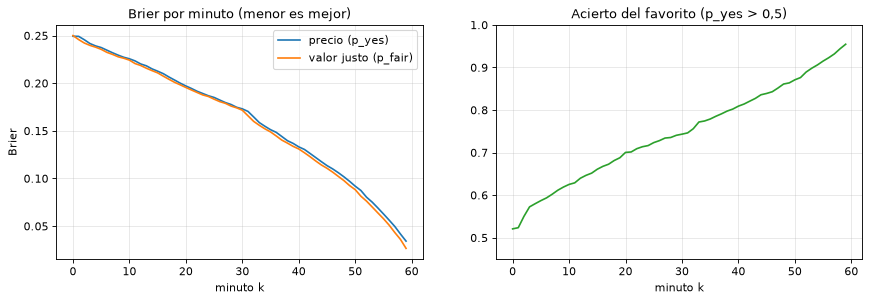

    brier_precio  brier_justo  acierto_favorito
k                                              
0         0.2493       0.2500            0.5208
15        0.2126       0.2108            0.6609
30        0.1731       0.1716            0.7433
45        0.1135       0.1107            0.8390
55        0.0628       0.0578            0.9150
59        0.0342       0.0266            0.9546


In [5]:
errores = grilla.assign(
    brier_precio=(grilla["p"] - grilla["outcome"]) ** 2,
    brier_justo=(grilla["p_fair"] - grilla["outcome"]) ** 2,
    acierto_favorito=(grilla["p"] > 0.5) == (grilla["outcome"] == 1),
)
por_minuto = errores.groupby("k")[["brier_precio", "brier_justo", "acierto_favorito"]].mean()

fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8))
ejes[0].plot(por_minuto.index, por_minuto["brier_precio"], label="precio (p_yes)")
ejes[0].plot(por_minuto.index, por_minuto["brier_justo"], label="valor justo (p_fair)")
ejes[0].set(title="Brier por minuto (menor es mejor)", xlabel="minuto k", ylabel="Brier")
ejes[0].legend()
ejes[1].plot(por_minuto.index, por_minuto["acierto_favorito"], color="C2")
ejes[1].set(title="Acierto del favorito (p_yes > 0,5)", xlabel="minuto k", ylim=(0.45, 1))
guardar(fig, "02_brier_por_minuto")
plt.show()

print(por_minuto.loc[[0, 15, 30, 45, 55, 59]].round(4).to_string())

### Lectura

- El precio está bien calibrado y mejora a medida que avanza la vela: el Brier baja de 0,249 en el minuto 0 a 0,034 en el 59, y el favorito acierta el 52 % en el minuto 0, el 74 % en el 30 y el 92 % en el 55.
- El valor justo (`p_fair`, calculado solo con el spot) le gana levemente al precio desde el minuto 15 (0,058 contra 0,063 en el 55). Pero `p_fair` usa un spot fresco y el precio tiene unos 52 s de atraso, así que parte de esa ventaja es solo el atraso (sección 5).

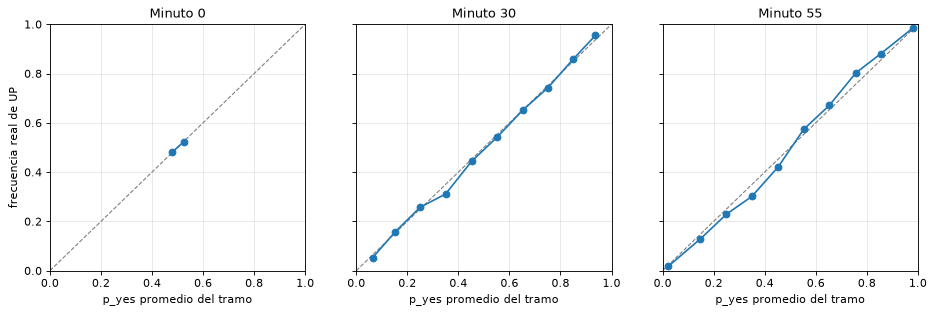

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for eje, k in zip(ejes, (0, 30, 55), strict=True):
    datos = grilla[grilla["k"] == k].dropna(subset=["p"])
    tramos = pd.cut(datos["p"], np.linspace(0, 1, 11), include_lowest=True)
    curva = datos.groupby(tramos, observed=True).agg(
        p=("p", "mean"), up=("outcome", "mean"), n=("p", "size")
    )
    curva = curva[curva["n"] >= 50]  # tramos con pocos casos no dicen nada
    eje.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
    eje.plot(curva["p"], curva["up"], marker="o")
    eje.set(title=f"Minuto {k}", xlabel="p_yes promedio del tramo", xlim=(0, 1), ylim=(0, 1))
ejes[0].set_ylabel("frecuencia real de UP")
guardar(fig, "03_confiabilidad")
plt.show()

### Lectura

- En el minuto 30 la curva sigue la diagonal: un precio de 0,7 gana alrededor del 70 % de las veces.
- En el minuto 55 la curva es más empinada que la diagonal: los resultados son más extremos de lo que dice el precio. Es lo esperable si el precio va atrasado respecto del spot: el mercado ya se movió y el último punto todavía no lo refleja.
- En el minuto 0 casi todos los precios están cerca de 0,5 y solo se muestran los tramos con al menos 50 casos.

## 5. ¿El precio reacciona tarde al spot?

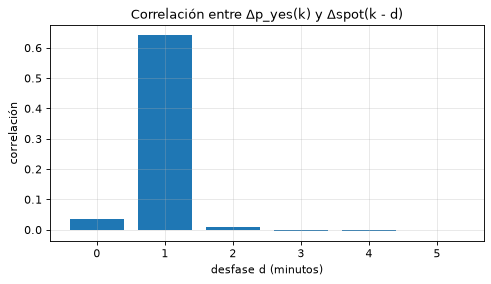

0    0.036
1    0.642
2    0.008
3   -0.005
4   -0.003
5   -0.002


In [7]:
grilla["dp"] = grilla.groupby("market_id")["p"].diff()
grilla["dx"] = grilla.groupby("market_id")["x"].diff()
correlacion = pd.Series(
    {d: grilla["dp"].corr(grilla.groupby("market_id")["dx"].shift(d)) for d in range(6)}
)

fig, eje = plt.subplots(figsize=(7, 3.5))
eje.bar(correlacion.index, correlacion.values)
eje.set(
    title="Correlación entre Δp_yes(k) y Δspot(k - d)",
    xlabel="desfase d (minutos)",
    ylabel="correlación",
)
guardar(fig, "04_desfase_precio_spot")
plt.show()
print(correlacion.round(3).to_string())

### Lectura

- El cambio del precio en el minuto `k` casi no se relaciona con el cambio del spot en el mismo minuto (0,04), pero sí con el del minuto anterior (**0,64**).
- No es un mercado lento: es el atraso de los datos. El punto de precio de `t` es de unos 52 s antes, así que su cambio refleja lo que hizo el spot un minuto antes. La medición con klines de 1 segundo de las decisiones previas (sección 2.3 de `docs/notas/decisiones_previas_al_diseno.md`) ya mostró que el mercado reacciona en segundos: alineando los relojes, la correlación cae de 0,90 a 0,22.
- Consecuencia: esta correlación no es una ventaja que el agente pueda explotar. Si el simulador ejecuta al precio viejo, el agente aprendería a aprovechar el atraso del feed (ver la sección 6).

## 6. ¿Cuánto se separa el valor justo del precio, y alcanza para cubrir los costos?

Regla simple, solo para medir: en cada minuto de 5 a 55, si `edge` supera un umbral se compra YES y si es menor que menos el umbral se compra NO, y se mantiene hasta la resolución. Se compara la entrada al precio de `t` (el que ve el agente) con la entrada al precio siguiente, con y sin costos (medio spread de 0,01 y comisión vigente). El intervalo toma el mercado como unidad, porque las decisiones de un mismo mercado no son independientes.

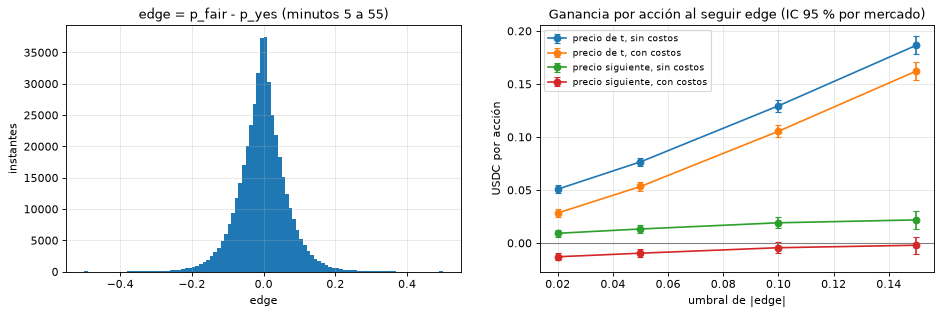

 umbral          entrada  costos  decisiones  mercados  ganancia  ic_bajo  ic_alto
   0.02      precio de t   False      304582      8683    0.0508   0.0473   0.0543
   0.02      precio de t    True      304582      8683    0.0283   0.0249   0.0318
   0.02 precio siguiente   False      304582      8683    0.0092   0.0057   0.0127
   0.02 precio siguiente    True      304582      8683   -0.0130  -0.0164  -0.0095
   0.05      precio de t   False      169204      8678    0.0766   0.0725   0.0806
   0.05      precio de t    True      169204      8678    0.0533   0.0493   0.0574
   0.05 precio siguiente   False      169204      8678    0.0133   0.0092   0.0173
   0.05 precio siguiente    True      169204      8678   -0.0096  -0.0136  -0.0055
   0.10      precio de t   False       56562      8183    0.1294   0.1240   0.1349
   0.10      precio de t    True       56562      8183    0.1055   0.1000   0.1109
   0.10 precio siguiente   False       56562      8183    0.0191   0.0137   0.0245
   0

In [8]:
def ganancia_por_accion(datos, umbral, columna, con_costos):
    """Ganancia por acción de comprar el lado que indica edge y mantener hasta la resolución."""
    si, no = datos[datos["edge"] > umbral], datos[datos["edge"] < -umbral]
    entrada_si = si[columna] + MEDIO_SPREAD * con_costos
    entrada_no = 1 - no[columna] + MEDIO_SPREAD * con_costos
    ganancia_si = si["outcome"] - entrada_si - comision(entrada_si) * con_costos
    ganancia_no = (1 - no["outcome"]) - entrada_no - comision(entrada_no) * con_costos
    return pd.concat([si["market_id"], no["market_id"]]), pd.concat([ganancia_si, ganancia_no])


def promedio_por_mercado(mercados, ganancias):
    """Media e intervalo del 95 % tomando el mercado como unidad, no cada decisión."""
    medias = ganancias.groupby(mercados.values).mean()
    error = medias.std() / math.sqrt(len(medias))
    return medias.mean(), medias.mean() - 1.96 * error, medias.mean() + 1.96 * error


zona = grilla[grilla["k"].between(5, 55)].dropna(subset=["p", "p_fair", "p_next"])
filas = []
for umbral in (0.02, 0.05, 0.10, 0.15):
    for columna, entrada in (("p", "precio de t"), ("p_next", "precio siguiente")):
        for con_costos in (False, True):
            mercados, ganancias = ganancia_por_accion(zona, umbral, columna, con_costos)
            media, bajo, alto = promedio_por_mercado(mercados, ganancias)
            filas.append(
                {
                    "umbral": umbral,
                    "entrada": entrada,
                    "costos": con_costos,
                    "decisiones": len(ganancias),
                    "mercados": mercados.nunique(),
                    "ganancia": media,
                    "ic_bajo": bajo,
                    "ic_alto": alto,
                }
            )
tabla = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
ejes[0].hist(zona["edge"].clip(-0.5, 0.5), bins=100)
ejes[0].set(title="edge = p_fair - p_yes (minutos 5 a 55)", xlabel="edge", ylabel="instantes")
for (entrada, con_costos), datos in tabla.groupby(["entrada", "costos"]):
    etiqueta = f"{entrada}, {'con' if con_costos else 'sin'} costos"
    ejes[1].errorbar(
        datos["umbral"],
        datos["ganancia"],
        yerr=[datos["ganancia"] - datos["ic_bajo"], datos["ic_alto"] - datos["ganancia"]],
        marker="o",
        capsize=3,
        label=etiqueta,
    )
ejes[1].axhline(0, color="grey", linewidth=1)
ejes[1].set(
    title="Ganancia por acción al seguir edge (IC 95 % por mercado)",
    xlabel="umbral de |edge|",
    ylabel="USDC por acción",
)
ejes[1].legend(fontsize=8)
guardar(fig, "05_ventaja_aparente")
plt.show()
print(tabla.round(4).to_string(index=False))

### Lectura

- **Al precio de `t`** la regla parece muy rentable: de 0,03 a 0,16 USDC por acción después de costos. Es la "ventaja fantasma" que anticipó la revisión de S1 a S8: se compra a un precio de hace casi un minuto con información del spot de ahora.
- **Al precio siguiente** la ventaja casi desaparece: de 0,009 a 0,022 por acción sin costos y entre -0,013 y -0,002 con costos. En ningún umbral el intervalo queda por encima de cero después de costos.
- Conclusiones para el diseño:
  - S4 (ejecutar en el precio siguiente) es indispensable. Sin eso, cualquier agente "le gana" al mercado por un defecto del simulador.
  - `edge` mide sobre todo el atraso del precio, como advirtió la revisión de S3. Los baselines tienen que recibir la misma información.
- Es un análisis en train, con una regla fija y sin elegir parámetros. Solo dice que no hay una ventaja obvia, no que no exista ninguna.

## 7. ¿Cambió el mercado con las comisiones?

Dentro de train hay mercados sin comisión y con comisión (desde el 06/03/2026).

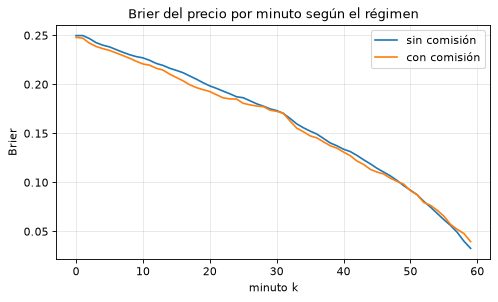

     régimen  mercados  brier_k0  brier_k30  brier_k55  correlación_desfase_1
sin comisión      6712    0.2497     0.1732     0.0620                 0.6417
con comisión      1971    0.2479     0.1725     0.0655                 0.6433


In [9]:
fig, eje = plt.subplots(figsize=(7, 3.8))
filas = []
regimen = errores.assign(dp=grilla["dp"], dx=grilla["dx"])
for con_comision, datos in regimen.groupby("fees_enabled"):
    curva = datos.groupby("k")["brier_precio"].mean()
    etiqueta = "con comisión" if con_comision else "sin comisión"
    eje.plot(curva.index, curva.values, label=etiqueta)
    lag1 = datos["dp"].corr(datos.groupby("market_id")["dx"].shift(1))
    filas.append(
        {
            "régimen": etiqueta,
            "mercados": datos["market_id"].nunique(),
            "brier_k0": curva.loc[0],
            "brier_k30": curva.loc[30],
            "brier_k55": curva.loc[55],
            "correlación_desfase_1": lag1,
        }
    )
eje.set(title="Brier del precio por minuto según el régimen", xlabel="minuto k", ylabel="Brier")
eje.legend()
guardar(fig, "06_regimen_comisiones")
plt.show()
print(pd.DataFrame(filas).round(4).to_string(index=False))

### Lectura

- No se ve un cambio: el Brier por minuto es prácticamente igual con y sin comisión (0,173 en el minuto 30 en ambos), y la correlación con desfase de 1 minuto también (0,642 y 0,643).
- Esto apoya el ADR-009: aplicar la comisión vigente a todos los mercados no mezcla dos mercados distintos. El riesgo R13 queda acotado en lo que mide esta EDA.

## 8. ¿Cuánto cuesta operar?

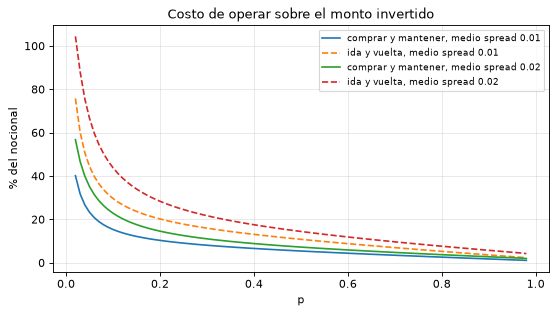

p = 0.5: mantener cuesta 0.0275 por acción; ida y vuelta, 0.0550
p = 0.7: mantener cuesta 0.0244 por acción; ida y vuelta, 0.0494
p = 0.9: mantener cuesta 0.0157 por acción; ida y vuelta, 0.0326


In [10]:
p = np.linspace(0.02, 0.98, 97)
fig, eje = plt.subplots(figsize=(8, 4))
for medio in (0.01, 0.02):
    compra = np.minimum(p + medio, 0.999)
    venta = np.maximum(p - medio, 0.001)
    mantener = (compra - p) + comision(compra)
    ida_y_vuelta = (compra - venta) + comision(compra) + comision(venta)
    eje.plot(p, 100 * mantener / compra, label=f"comprar y mantener, medio spread {medio}")
    etiqueta = f"ida y vuelta, medio spread {medio}"
    eje.plot(p, 100 * ida_y_vuelta / compra, linestyle="--", label=etiqueta)
eje.set(title="Costo de operar sobre el monto invertido", xlabel="p", ylabel="% del nocional")
eje.legend(fontsize=8)
guardar(fig, "07_costo_de_operar")
plt.show()
for precio in (0.5, 0.7, 0.9):
    compra = precio + MEDIO_SPREAD
    print(
        f"p = {precio}: mantener cuesta {MEDIO_SPREAD + comision(compra):.4f} por acción; "
        f"ida y vuelta, {2 * MEDIO_SPREAD + comision(compra) + comision(precio - MEDIO_SPREAD):.4f}"
    )

### Lectura

- Comprar con `p = 0,5` y mantener hasta la resolución cuesta 0,0275 USDC por acción, un 5,4 % de lo invertido. Comprar y vender antes cuesta el doble, 0,055.
- Con `p = 0,9`, mantener cuesta 0,016 por acción (1,7 %): operar lejos de 0,5 es más barato, porque la comisión es proporcional a `p × (1 - p)`.
- Comparado con la sección 6: la ventaja bruta al precio siguiente (0,01 a 0,02 por acción) es menor que el costo de mantener (0,016 a 0,028).

## 9. ¿Hay sesgos por hora o por día?

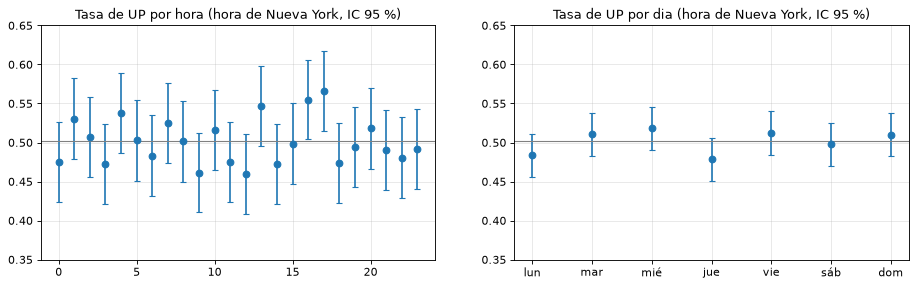

hora: dispersión 0.0298, valor p de la permutación 0.178
dia: dispersión 0.0154, valor p de la permutación 0.318


In [11]:
inicio = pd.to_datetime(train["w0"], unit="s", utc=True).dt.tz_convert("America/New_York")
train["hora"] = inicio.dt.hour
train["dia"] = inicio.dt.day_of_week
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]


def dispersion(grupo):
    return train.groupby(grupo)["outcome"].mean().std()


# Prueba de permutación: ¿la dispersión entre horas (o días) es mayor que la del azar?
rng = np.random.default_rng(0)
resultados = train["outcome"].to_numpy()
pruebas = {}
for grupo in ("hora", "dia"):
    observada = dispersion(grupo)
    azar = [
        pd.Series(rng.permutation(resultados)).groupby(train[grupo]).mean().std()
        for _ in range(2000)
    ]
    pruebas[grupo] = (observada, float(np.mean(np.array(azar) >= observada)))

fig, ejes = plt.subplots(1, 2, figsize=(14, 3.8))
for eje, grupo, etiquetas in ((ejes[0], "hora", None), (ejes[1], "dia", dias)):
    tasas = train.groupby(grupo)["outcome"].agg(["mean", "count"])
    error = 1.96 * np.sqrt(tasas["mean"] * (1 - tasas["mean"]) / tasas["count"])
    eje.errorbar(tasas.index, tasas["mean"], yerr=error, marker="o", linestyle="", capsize=3)
    eje.axhline(train["outcome"].mean(), color="grey", linewidth=1)
    eje.set(title=f"Tasa de UP por {grupo} (hora de Nueva York, IC 95 %)", ylim=(0.35, 0.65))
    if etiquetas:
        eje.set_xticks(range(7), etiquetas)
guardar(fig, "08_sesgos_hora_dia")
plt.show()
for grupo, (observada, valor_p) in pruebas.items():
    print(f"{grupo}: dispersión {observada:.4f}, valor p de la permutación {valor_p:.3f}")

### Lectura

- La tasa de UP va de 0,46 a 0,57 según la hora y se mueve menos entre días. La prueba de permutación no encuentra más dispersión que la del azar (valor p de 0,18 por hora y 0,32 por día).
- No hay evidencia para agregar la hora o el día como features.

## 10. Conclusiones

1. **Los datos alcanzan y son de buena calidad:** 8 683 mercados en train con un punto de precio por minuto, y apenas un 0,5 % descartado por calidad.
2. **El precio está bien calibrado:** el favorito acierta del 52 % al inicio de la vela al 92 % en el minuto 55.
3. **La ventaja aparente viene del reloj, no del mercado:** el precio que se ve en cada minuto tiene unos 52 s de atraso. Ejecutando en el precio siguiente, la ventaja de `edge` baja a 1 o 2 centavos por acción y no cubre los costos. Esto respalda S4 (ejecución en el precio siguiente) y la advertencia sobre `edge` en S3.
4. **Las comisiones no cambiaron el comportamiento del precio,** lo que apoya el ADR-009.
5. **No hay sesgos por hora ni por día.**
6. **Qué esperar del entrenamiento:** en train no aparece una estrategia simple rentable después de costos. La comparación principal sigue siendo contra los baselines con los mismos costos (D1), y es probable que el agente aprenda a operar poco o nada (R5 y R14). Según D4, eso se reporta y el proyecto sigue.